<a href="https://colab.research.google.com/github/2025ct05044-cmd/MLOps-Assignment/blob/main/Notebook/03_MLflow_Experiment_Tracking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — MLflow Experiment Tracking
**Project:** Heart Disease Prediction — MLOps Assignment 01

This notebook completes Assignment Task 3 (5 marks) by recording reproducible experiments for Logistic Regression and Random Forest.

It logs:
- Model parameters and run tags
- Five-fold stratified cross-validation metrics (mean and standard deviation)
- Held-out test metrics: accuracy, precision, recall, F1 and ROC-AUC
- Confusion matrices, ROC curves, environment metadata and fitted model pipelines
- A comparison CSV, the selected pipeline and selection metadata

**Prerequisite:** Run `01_EDA_and_Data_Preparation.ipynb` first so that `data/processed/cleaned_heart_disease.csv` exists. Notebook 02 should also be run to complete and verify model development. This notebook's candidate parameters are explicit and reproducible; if Notebook 02 reports tuned parameters, update `model_configs` below to match them.

## 1. Install dependencies
Run this cell once in the active Colab or Jupyter environment.

In [21]:
%pip -q install mlflow scikit-learn pandas numpy matplotlib seaborn joblib

## 2. Import libraries and configure reproducibility

In [22]:
from pathlib import Path
import json
import os
import platform
import subprocess
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("MLflow:", mlflow.__version__)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.13.16
MLflow: 3.17.1
scikit-learn: 1.6.1
pandas: 2.2.3
NumPy: 2.1.3


## 3. Resolve the project root and create output folders
The notebook reuses the existing Colab repository when possible, otherwise it checks the current working directory. It does not overwrite your source notebooks.

In [23]:
REPO_NAME = "MLOps-Assignment"
REPO_URL = "https://github.com/2025ct05044-cmd/MLOps-Assignment.git"
DATA_RELATIVE_PATH = Path("data/processed/cleaned_heart_disease.csv")

candidate_roots = [
    Path.cwd().resolve(),
    Path("/content") / REPO_NAME,
    Path.cwd() / REPO_NAME,
]

PROJECT_ROOT = None
for candidate in candidate_roots:
    candidate = candidate.resolve()
    if (candidate / DATA_RELATIVE_PATH).exists():
        PROJECT_ROOT = candidate
        break

# Clone the public repository only if no local copy containing the prepared dataset was found.
if PROJECT_ROOT is None:
    clone_path = Path("/content") / REPO_NAME
    if not clone_path.exists():
        subprocess.run(["git", "clone", REPO_URL, str(clone_path)], check=True)
    if (clone_path / DATA_RELATIVE_PATH).exists():
        PROJECT_ROOT = clone_path.resolve()

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/processed/cleaned_heart_disease.csv. "
        "Run Notebook 01 first and ensure the cleaned CSV is present in "
        "the MLOps-Assignment/data/processed/ folder."
    )

os.chdir(PROJECT_ROOT)
DATA_PATH = PROJECT_ROOT / DATA_RELATIVE_PATH
MLRUNS_DIR = PROJECT_ROOT / "mlruns"
REPORTS_DIR = PROJECT_ROOT / "reports"
SCREENSHOTS_DIR = PROJECT_ROOT / "screenshots" / "mlflow"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [MLRUNS_DIR, REPORTS_DIR, SCREENSHOTS_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())
print("MLflow directory:", MLRUNS_DIR)
print("Reports directory:", REPORTS_DIR)
print("Models directory:", MODELS_DIR)
print("MLflow plots directory:", SCREENSHOTS_DIR)

Project root: /content/MLOps-Assignment
Dataset path: /content/MLOps-Assignment/data/processed/cleaned_heart_disease.csv
Dataset exists: True
MLflow directory: /content/MLOps-Assignment/mlruns
Reports directory: /content/MLOps-Assignment/reports
Models directory: /content/MLOps-Assignment/models
MLflow plots directory: /content/MLOps-Assignment/screenshots/mlflow


## 4. Configure the MLflow experiment
MLflow stores local run records under the repository's `mlruns/` directory. Colab storage is temporary, so download or copy artifacts before ending the runtime.

In [24]:
from pathlib import Path
import mlflow

# Use the existing project directory
MLRUNS_DIR = Path(MLRUNS_DIR)
MLRUNS_DIR.mkdir(parents=True, exist_ok=True)

# Store experiment metadata in SQLite
MLFLOW_DB = MLRUNS_DIR.parent / "mlflow.db"
TRACKING_URI = f"sqlite:///{MLFLOW_DB.resolve().as_posix()}"

mlflow.set_tracking_uri(TRACKING_URI)

EXPERIMENT_NAME = "heart-disease-model-development"

# Create the experiment if it doesn't already exist
mlflow.set_experiment(EXPERIMENT_NAME)

experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment ID:", experiment.experiment_id)
print("Experiment name:", experiment.name)
print("Database exists:", MLFLOW_DB.exists())

Tracking URI: sqlite:////content/MLOps-Assignment/mlflow.db
Experiment ID: 1
Experiment name: heart-disease-model-development
Database exists: True


## 5. Load and validate the processed dataset
The expected columns match the Heart Disease dataset used by Notebook 01. Numeric feature conversion is checked before modeling; invalid feature values become missing and are handled inside the training pipeline.

In [25]:
df = pd.read_csv(DATA_PATH)

EXPECTED_COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "target",
]
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {missing_columns}")

df = df[EXPECTED_COLUMNS].copy()
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

for column in EXPECTED_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

if df["target"].isna().any():
    raise ValueError("Target contains missing or non-numeric values.")
df["target"] = df["target"].astype(int)

if not set(df["target"].unique()).issubset({0, 1}):
    raise ValueError("Target must contain only binary values 0 and 1.")
if df["target"].nunique() != 2:
    raise ValueError("Both target classes must be present.")

print("Dataset shape after duplicate removal:", df.shape)
print("Duplicate rows removed:", duplicate_count)
print("\nTarget counts:")
display(df["target"].value_counts().sort_index().rename_axis("target").to_frame("count"))
print("\nMissing values per column:")
display(df.isna().sum().rename("missing_count").to_frame())
display(df.head())

Dataset shape after duplicate removal: (297, 14)
Duplicate rows removed: 0

Target counts:


,count
target,
0,160
1,137



Missing values per column:


,missing_count
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 6. Split data and define preprocessing
A stratified hold-out test set is kept separate from cross-validation. Imputation, scaling and one-hot encoding are inside the pipeline, so each CV fold learns preprocessing only from its training portion.

In [26]:
X = df.drop(columns="target")
y = df["target"]

continuous_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = [
    "sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("continuous", numeric_pipeline, continuous_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Continuous features:", continuous_features)
print("Categorical features:", categorical_features)
print("Training target distribution:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Training rows: 237
Test rows: 60
Continuous features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Training target distribution:


,proportion
target,
0,0.540084
1,0.459916


## 7. Define candidate model configurations
These are reproducible baseline configurations. If your completed Notebook 02 contains tuned hyperparameters, update the estimator and logged `params` below so the tracking matches the model-development results.

In [27]:
model_configs = {
    "logistic_regression": {
        "estimator": LogisticRegression(
            C=1.0,
            solver="liblinear",
            class_weight=None,
            max_iter=2000,
            random_state=RANDOM_STATE,
        ),
        "params": {
            "C": 1.0,
            "solver": "liblinear",
            "class_weight": "None",
            "max_iter": 2000,
        },
    },
    "random_forest": {
        "estimator": RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            class_weight=None,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {
            "n_estimators": 200,
            "max_depth": "None",
            "min_samples_split": 2,
            "min_samples_leaf": 1,
            "class_weight": "None",
        },
    },
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

print("Candidate models:", list(model_configs))
print("Cross-validation folds:", cv.get_n_splits())

Candidate models: ['logistic_regression', 'random_forest']
Cross-validation folds: 5


## 8. Train, evaluate and log each experiment
Each run logs parameters and tags, five-fold cross-validation means and standard deviations, held-out test metrics, confusion matrix, ROC curve, environment metadata and the fitted preprocessing/model pipeline.

In [28]:
run_summaries = []

for model_name, config in model_configs.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(config["estimator"])),
    ])

    with mlflow.start_run(run_name=model_name) as run:
        mlflow.set_tags({
            "project": "heart-disease-mlops",
            "dataset": "UCI Heart Disease",
            "model_family": model_name,
            "assignment_task": "experiment_tracking",
        })

        mlflow.log_params(config["params"])
        mlflow.log_params({
            "random_state": RANDOM_STATE,
            "test_size": 0.20,
            "cv_folds": 5,
            "training_rows": len(X_train),
            "test_rows": len(X_test),
            "feature_count": X.shape[1],
        })

        cv_scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            error_score="raise",
        )

        cv_summary = {}
        for metric_name in scoring:
            values = cv_scores[f"test_{metric_name}"]
            cv_summary[f"cv_{metric_name}_mean"] = float(values.mean())
            cv_summary[f"cv_{metric_name}_std"] = float(values.std())
        mlflow.log_metrics(cv_summary)

        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)
        probabilities = pipeline.predict_proba(X_test)[:, 1]

        test_metrics = {
            "test_accuracy": float(accuracy_score(y_test, predictions)),
            "test_precision": float(precision_score(y_test, predictions, zero_division=0)),
            "test_recall": float(recall_score(y_test, predictions, zero_division=0)),
            "test_f1": float(f1_score(y_test, predictions, zero_division=0)),
            "test_roc_auc": float(roc_auc_score(y_test, probabilities)),
        }
        mlflow.log_metrics(test_metrics)

        # Save and log confusion matrix
        cm_path = SCREENSHOTS_DIR / f"{model_name}_confusion_matrix.png"
        ConfusionMatrixDisplay.from_predictions(
            y_test,
            predictions,
            display_labels=["No disease", "Disease"],
            colorbar=False,
        )
        plt.title(f"Confusion Matrix: {model_name}")
        plt.tight_layout()
        plt.savefig(cm_path, dpi=300, bbox_inches="tight")
        plt.close()
        mlflow.log_artifact(str(cm_path), artifact_path="plots")

        # Save and log ROC curve
        roc_path = SCREENSHOTS_DIR / f"{model_name}_roc_curve.png"
        RocCurveDisplay.from_predictions(y_test, probabilities, name=model_name)
        plt.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
        plt.title(f"ROC Curve: {model_name}")
        plt.tight_layout()
        plt.savefig(roc_path, dpi=300, bbox_inches="tight")
        plt.close()
        mlflow.log_artifact(str(roc_path), artifact_path="plots")

        # Record runtime/library versions for reproducibility
        environment_metadata = {
            "python_version": sys.version,
            "platform": platform.platform(),
            "mlflow_version": mlflow.__version__,
            "pandas_version": pd.__version__,
            "numpy_version": np.__version__,
            "scikit_learn_version": sklearn.__version__,
            "joblib_version": joblib.__version__,
        }
        environment_path = REPORTS_DIR / f"{model_name}_environment.json"
        environment_path.write_text(
            json.dumps(environment_metadata, indent=2),
            encoding="utf-8",
        )
        mlflow.log_artifact(str(environment_path), artifact_path="environment")

        # Log the fitted preprocessing + model pipeline as an MLflow artifact
        model_info = mlflow.sklearn.log_model(
          sk_model=pipeline,
          name=f"{model_name.lower().replace(' ', '_')}_model",
          serialization_format="pickle",
          input_example=X_train.head(3),
        )

        run_summaries.append({
            "run_id": run.info.run_id,
            "model": model_name,
            **cv_summary,
            **test_metrics,
            "model_uri": model_info.model_uri,
        })

        print(f"Finished and logged run: {model_name} | run_id={run.info.run_id}")

run_summary_df = pd.DataFrame(run_summaries).sort_values(
    "test_roc_auc", ascending=False
).reset_index(drop=True)

display(run_summary_df)

2026/10/19 08:57:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling 

Finished and logged run: logistic_regression | run_id=2e29f14283e24ce681d8b899a2052dbc


2026/10/19 08:57:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling 

Finished and logged run: random_forest | run_id=51a72c6598544ba9adce22289e516662


,run_id,model,cv_accuracy_mean,cv_accuracy_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_roc_auc_std,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,model_uri
0,2e29f14283e24ce681d8b899a2052dbc,logistic_regression,0.822252,0.082051,0.839086,0.098400,0.769264,0.115712,0.797828,0.089963,0.902782,0.069651,0.816667,0.869565,0.714286,0.784314,0.940848,models:/m-843c00241c864cc7b1bf9ad15331578f
1,51a72c6598544ba9adce22289e516662,random_forest,0.797518,0.056161,0.814791,0.089467,0.741991,0.109742,0.769131,0.066749,0.897413,0.055123,0.833333,0.846154,0.785714,0.814815,0.934152,models:/m-038201c416dc4d4e9a495c5648b72615


## 9. Compare runs and save the selected model
The best candidate is selected by held-out test ROC-AUC for this assignment workflow. The held-out set should ideally be used only for final comparison, not repeated tuning.

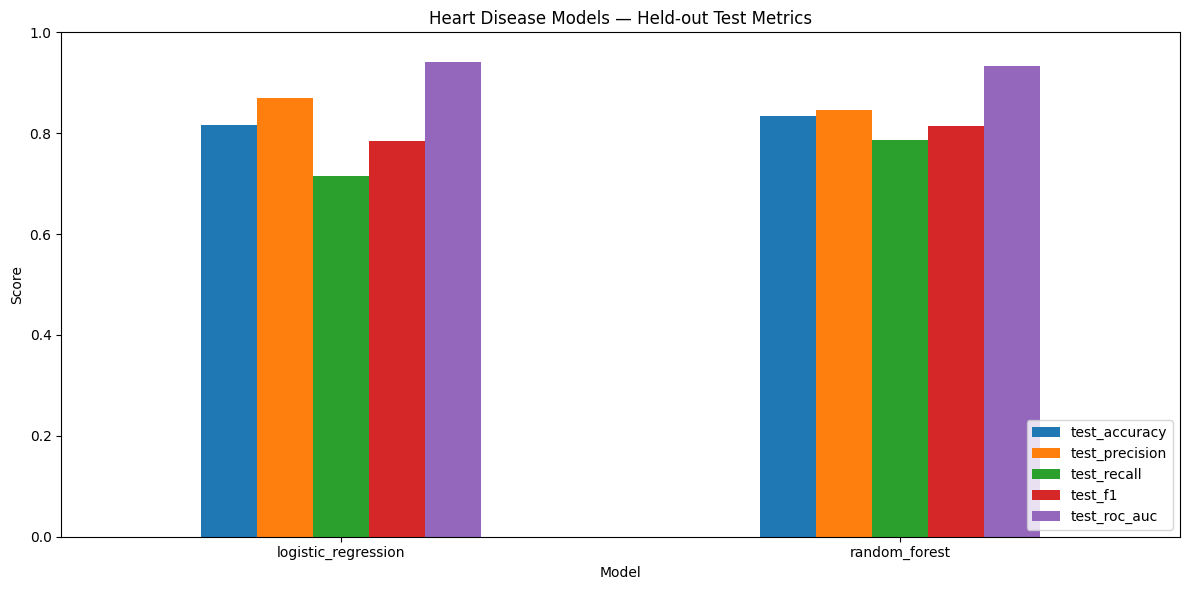

Comparison CSV saved: /content/MLOps-Assignment/reports/mlflow_run_comparison.csv
Comparison plot saved: /content/MLOps-Assignment/reports/mlflow_model_comparison.png
Selected pipeline saved: /content/MLOps-Assignment/models/heart_disease_mlflow_selected_pipeline.joblib
Selection metadata saved: /content/MLOps-Assignment/models/heart_disease_mlflow_selection_metadata.json
Selected model: logistic_regression


In [29]:
comparison_path = REPORTS_DIR / "mlflow_run_comparison.csv"
run_summary_df.to_csv(comparison_path, index=False)

# Save a metric comparison plot for assignment evidence
metric_columns = ["test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc"]
ax = run_summary_df.set_index("model")[metric_columns].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1), rot=0
)
ax.set_title("Heart Disease Models — Held-out Test Metrics")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(loc="lower right")
plt.tight_layout()
comparison_plot_path = REPORTS_DIR / "mlflow_model_comparison.png"
plt.savefig(comparison_plot_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

best_run = run_summary_df.iloc[0]
best_model_uri = best_run["model_uri"]
best_pipeline = mlflow.sklearn.load_model(best_model_uri)

selected_model_path = MODELS_DIR / "heart_disease_mlflow_selected_pipeline.joblib"
joblib.dump(best_pipeline, selected_model_path)

selection_metadata = {
    "selection_metric": "test_roc_auc",
    "selected_model": best_run["model"],
    "run_id": best_run["run_id"],
    "model_uri": best_model_uri,
    "test_roc_auc": float(best_run["test_roc_auc"]),
    "random_state": RANDOM_STATE,
    "experiment_name": EXPERIMENT_NAME,
}
selection_path = MODELS_DIR / "heart_disease_mlflow_selection_metadata.json"
selection_path.write_text(json.dumps(selection_metadata, indent=2), encoding="utf-8")

print("Comparison CSV saved:", comparison_path)
print("Comparison plot saved:", comparison_plot_path)
print("Selected pipeline saved:", selected_model_path)
print("Selection metadata saved:", selection_path)
print("Selected model:", best_run["model"])

## 10. Reload smoke test
Load the selected pipeline from disk and verify that it produces predictions and probabilities for unseen test rows.

In [30]:
reloaded_pipeline = joblib.load(selected_model_path)
sample_rows = X_test.head(5)
sample_predictions = reloaded_pipeline.predict(sample_rows)
sample_probabilities = reloaded_pipeline.predict_proba(sample_rows)[:, 1]

smoke_test = pd.DataFrame({
    "actual_target": y_test.loc[sample_rows.index].to_numpy(),
    "prediction": sample_predictions,
    "disease_probability": sample_probabilities,
})
display(smoke_test)

if len(smoke_test) == 0 or smoke_test["prediction"].isna().any():
    raise RuntimeError("Model reload smoke test failed.")
print("Reload smoke test passed.")

,actual_target,prediction,disease_probability
0,0,0,0.025388
1,0,0,0.058126
2,0,0,0.463345
3,0,0,0.421209
4,0,0,0.319365


Reload smoke test passed.


## 11. Verify all required artifacts
Every row should show `True`. If a check fails, do not mark Task 3 complete until the issue is fixed.

In [31]:
artifacts = [
    DATA_PATH,
    comparison_path,
    comparison_plot_path,
    selected_model_path,
    selection_path,
    SCREENSHOTS_DIR / "logistic_regression_confusion_matrix.png",
    SCREENSHOTS_DIR / "logistic_regression_roc_curve.png",
    SCREENSHOTS_DIR / "random_forest_confusion_matrix.png",
    SCREENSHOTS_DIR / "random_forest_roc_curve.png",
    REPORTS_DIR / "logistic_regression_environment.json",
    REPORTS_DIR / "random_forest_environment.json",
]

artifact_status = pd.DataFrame({
    "artifact": [
        str(path.relative_to(PROJECT_ROOT)) if path.is_relative_to(PROJECT_ROOT) else str(path)
        for path in artifacts
    ],
    "exists": [path.exists() for path in artifacts],
})
display(artifact_status)

if not artifact_status["exists"].all():
    missing = artifact_status.loc[~artifact_status["exists"], "artifact"].tolist()
    raise RuntimeError(f"Missing expected artifacts: {missing}")

if len(run_summary_df) < 2:
    raise RuntimeError("Expected at least two MLflow runs.")

print("All expected Notebook 03 artifacts were created successfully.")

,artifact,exists
0,data/processed/cleaned_heart_disease.csv,True
1,reports/mlflow_run_comparison.csv,True
2,reports/mlflow_model_comparison.png,True
3,models/heart_disease_mlflow_selected_pipeline....,True
4,models/heart_disease_mlflow_selection_metadata...,True
5,screenshots/mlflow/logistic_regression_confusi...,True
6,screenshots/mlflow/logistic_regression_roc_cur...,True
7,screenshots/mlflow/random_forest_confusion_mat...,True
8,screenshots/mlflow/random_forest_roc_curve.png,True
9,reports/logistic_regression_environment.json,True


All expected Notebook 03 artifacts were created successfully.


In [33]:
#12. Open the MLflow UI

from pathlib import Path
import mlflow

print("Tracking URI:", mlflow.get_tracking_uri())
print("Current directory:", Path.cwd())
print("Database files:", list(Path("/content").rglob("mlflow.db"))[:10])

Tracking URI: sqlite:////content/MLOps-Assignment/mlflow.db
Current directory: /content/MLOps-Assignment
Database files: [PosixPath('/content/MLOps-Assignment/mlflow.db')]


In [34]:
import subprocess
import sys
import time
import mlflow

tracking_uri = mlflow.get_tracking_uri()

print("Using tracking database:", tracking_uri)

mlflow_process = subprocess.Popen(
    [
        sys.executable, "-m", "mlflow", "ui",
        "--backend-store-uri", tracking_uri,
        "--host", "0.0.0.0",
        "--port", "5000",
        "--allowed-hosts", "*"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(5)

if mlflow_process.poll() is None:
    print("MLflow UI started successfully.")
else:
    print("MLflow UI failed to start:")
    print(mlflow_process.stdout.read())

Using tracking database: sqlite:////content/MLOps-Assignment/mlflow.db
MLflow UI started successfully.


In [35]:
from google.colab.output import eval_js

ui_url = eval_js("google.colab.kernel.proxyPort(5000)")
print("Open your MLflow UI here:")
print(ui_url)

Open your MLflow UI here:
https://5000-m-s-kkb-ase1a0-1i18flu0bzf3h-a.asia-east1-0.prod.colab.dev


In [38]:
import subprocess

subprocess.run(
    ["pkill", "-f", "mlflow"],
    capture_output=True
)

print("Attempted to stop the existing MLflow UI.")

Attempted to stop the existing MLflow UI.
